# 7. Image and Video Inpainting

Practice for week 7: diffusion (Laplace) inpainting, exemplar-based "smart cut-and-paste", object removal
from video with a temporal median, and repairing vertical scratches in old film.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=3, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

def make_image(n=256):
    y, x = np.mgrid[:n, :n] / n
    img = 0.25 + 0.4 * x + 0.1 * np.sin(6 * np.pi * y)
    img[(x - 0.3) ** 2 + (y - 0.35) ** 2 < 0.04] = 0.9
    img[(x > 0.55) & (x < 0.9) & (y > 0.55) & (y < 0.85)] = 0.15
    s = (y > 0.7) & (x < 0.45)
    img[s] = 0.5 + 0.3 * np.sign(np.sin(2 * np.pi * 40 * x[s]))
    return img.clip(0, 1)

def psnr(a, b):
    return 10 * np.log10(1 / np.mean((a - b) ** 2))

img = make_image()

## 7.1 Diffusion inpainting

Fill the hole by solving Laplace's equation inside it with the known pixels as boundary values (repeat:
each missing pixel becomes the average of its 4 neighbours). Smooth regions and the disk edge come out
fine. The striped texture does not: diffusion can only produce smooth fills.

In the transport form `∇L · N = 0` with `N = (∇I)^⊥` one propagates `L = ΔI` along the isophotes.
Propagating `L = I` itself would say nothing, because `∇I · (∇I)^⊥ = 0` for any image.

PSNR inside the hole: smooth bar 35.0 dB, thin line 33.3 dB, textured square 10.4 dB


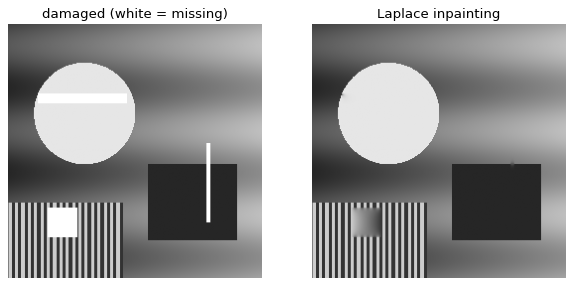

In [2]:
mask = np.zeros(img.shape, bool)
mask[70:80, 30:120] = True                  # a bar across the disk
mask[185:215, 40:70] = True                 # a square in the stripes
mask[120:200, 200:204] = True               # a thin vertical line

def laplace_inpaint(u, mask, iters=3000):
    u = u.copy(); u[mask] = u[~mask].mean()
    for _ in range(iters):
        avg = (np.roll(u, 1, 0) + np.roll(u, -1, 0) + np.roll(u, 1, 1) + np.roll(u, -1, 1)) / 4
        u[mask] = avg[mask]
    return u

damaged = np.where(mask, 1.0, img)
filled = laplace_inpaint(img, mask)
print(f"PSNR inside the hole: smooth bar {psnr(filled[70:80, 30:120], img[70:80, 30:120]):.1f} dB, "
      f"thin line {psnr(filled[120:200, 200:204], img[120:200, 200:204]):.1f} dB, "
      f"textured square {psnr(filled[185:215, 40:70], img[185:215, 40:70]):.1f} dB")
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
for a, u, t in zip(axes, [damaged, filled], ["damaged (white = missing)", "Laplace inpainting"]):
    a.imshow(u, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.show()

## 7.2 Exemplar-based inpainting (smart cut-and-paste)

Fill one missing pixel at a time, from the border of the hole inward. For each, compare its partially known
7×7 patch with every fully known patch in the image and copy the centre of the best match. This copies
texture instead of blurring it. With N missing pixels and M candidate patches it costs about N·M patch
comparisons.

900 missing pixels x 7540 candidates = 6,786,000 patch comparisons
mean abs error in the hole: diffusion 0.269, exemplar 0.000


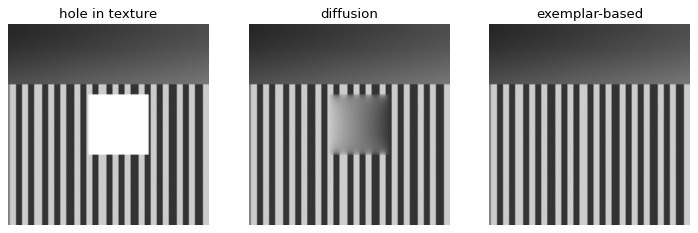

In [3]:
crop = img[150:250, 0:100].copy()
hole = np.zeros(crop.shape, bool); hole[35:65, 40:70] = True
u = np.where(hole, np.nan, crop)
k = 3
win = np.lib.stride_tricks.sliding_window_view(np.pad(u, k, constant_values=np.nan), (2 * k + 1, 2 * k + 1))
cands = win[~np.isnan(win).any((-2, -1))].reshape(-1, (2 * k + 1) ** 2)

missing, comparisons = hole.copy(), 0
P = np.pad(u, k, constant_values=np.nan)
while missing.any():
    known = ~missing
    border = missing & (np.roll(known, 1, 0) | np.roll(known, -1, 0) | np.roll(known, 1, 1) | np.roll(known, -1, 1))
    for y0, x0 in zip(*np.nonzero(border)):
        patch = P[y0:y0 + 2 * k + 1, x0:x0 + 2 * k + 1].ravel()
        ok = ~np.isnan(patch)
        ssd = ((cands[:, ok] - patch[ok]) ** 2).sum(1)
        P[y0 + k, x0 + k] = cands[ssd.argmin(), len(patch) // 2]
        comparisons += len(cands)
    missing &= ~border
exemplar = P[k:-k, k:-k]
diffusion = laplace_inpaint(crop, hole)
print(f"{hole.sum()} missing pixels x {len(cands)} candidates = {comparisons:,} patch comparisons")
print(f"mean abs error in the hole: diffusion {np.abs(diffusion - crop)[hole].mean():.3f}, exemplar {np.abs(exemplar - crop)[hole].mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for a, v, t in zip(axes, [np.where(hole, 1.0, crop), diffusion, exemplar], ["hole in texture", "diffusion", "exemplar-based"]):
    a.imshow(v, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.show()

## 7.3 Video: removing a fast-moving object

A static background and a square that crosses the frame in a few frames. At each `(x, y)` the object is
present only briefly, so the median over time ignores it as an outlier. A temporal average leaves a
ghost trail.

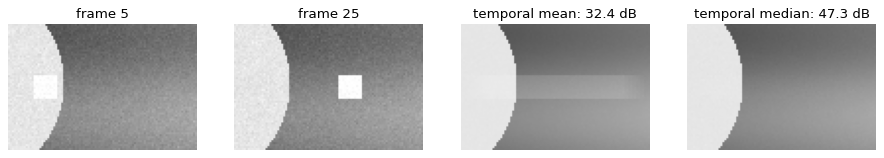

In [4]:
bg = img[60:124, 100:196]
frames = np.repeat(bg[None], 40, 0).copy()
for t in range(40):
    x0 = 3 + 2 * t
    frames[t, 26:38, x0:x0 + 12] = 1.0
frames += rng.normal(0, 0.02, frames.shape)

mean_bg, median_bg = frames.mean(0), np.median(frames, 0)
fig, axes = plt.subplots(1, 4, figsize=(14, 2.8))
for a, v, t in zip(axes, [frames[5], frames[25], mean_bg, median_bg],
                   ["frame 5", "frame 25", f"temporal mean: {psnr(mean_bg, bg):.1f} dB", f"temporal median: {psnr(median_bg, bg):.1f} dB"]):
    a.imshow(v, cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.show()

## 7.4 Vertical scratches in old film

Bright 1-pixel vertical lines. Vertical lines are the θ = 0 column of the Hough accumulator, which for
vertical lines reduces to voting per column: sum the signed deviation of each pixel from its left/right
neighbours along every column and look for peaks. Because the scratches are thin, linear interpolation
from the two neighbours is enough to repair them.

detected scratch columns: [17, 52, 90, 91]
PSNR: scratched 20.4 dB, repaired 49.6 dB


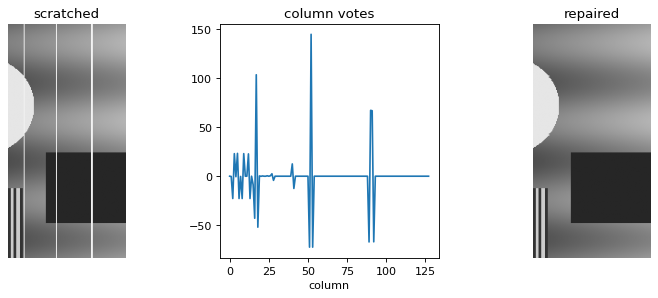

In [5]:
clean = img[:, 100:228]
scratched = clean.copy()
for c in [17, 52, 90, 91]:
    scratched[:, c] = 0.95
dev = (scratched[:, 1:-1] - (scratched[:, :-2] + scratched[:, 2:]) / 2).sum(0)   # signed: bright lines vote up
score = np.r_[0, dev, 0]
cols = np.nonzero(score > 0.3 * score.max())[0]
print("detected scratch columns:", cols.tolist())

repaired = scratched.copy()
good = np.setdiff1d(np.arange(clean.shape[1]), cols)
for r in range(clean.shape[0]):
    repaired[r, cols] = np.interp(cols, good, scratched[r, good])
print(f"PSNR: scratched {psnr(scratched, clean):.1f} dB, repaired {psnr(repaired, clean):.1f} dB")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(scratched, cmap="gray", vmin=0, vmax=1); axes[0].set_title("scratched")
axes[1].plot(score); axes[1].set_title("column votes"); axes[1].set_xlabel("column")
axes[2].imshow(repaired, cmap="gray", vmin=0, vmax=1); axes[2].set_title("repaired")
axes[0].axis("off"); axes[2].axis("off"); plt.show()